In [2]:
import random
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

In [3]:
DATA = Path('data')
IMAGE_SIZE = 32
K_VALUES = list(range(1, 16, 2))
NUM_TESTS = 5
SYMBOL_NAMES = {'times': '×'}
best_k = 1

files, labels = [], []

for folder in sorted(DATA.iterdir()):
    if folder.is_dir():
        for path in sorted(folder.iterdir()):
            if path.is_file() and path.suffix.lower() in {
                '.jpg', '.jpeg', '.png', '.bmp'
            }:
                files.append(path)
                labels.append(folder.name)

train_paths, test_paths, y_train, y_test = train_test_split(
    files, labels,
    test_size=0.3,
    stratify=labels,
    random_state=42
)

test_files = {}
for path, label in zip(test_paths, y_test):
    test_files.setdefault(label, []).append(path)

print('Количество классов:', len(set(labels)))


Количество классов: 21


In [4]:
def prepare_symbol(image):
    image = cv2.erode(image, np.ones((3, 3), np.uint8))
    _, binary = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY_INV)

    points = cv2.findNonZero(binary)
    if points is None:
        raise ValueError('Пустое изображение')

    x, y, w, h = cv2.boundingRect(points)
    symbol = binary[y:y+h, x:x+w]

    scale = 24 / max(h, w)
    width = max(1, round(w * scale))
    height = max(1, round(h * scale))

    symbol = cv2.resize(
        symbol, (width, height), interpolation=cv2.INTER_AREA
    )
    symbol = np.where(symbol > 0, 255, 0).astype(np.uint8)

    result = np.zeros((IMAGE_SIZE, IMAGE_SIZE), np.uint8)
    x = (IMAGE_SIZE - width) // 2
    y = (IMAGE_SIZE - height) // 2
    result[y:y+height, x:x+width] = symbol

    return result.flatten().astype(np.float32) / 255


def make_dataset(paths):
    vectors = []

    for path in paths:
        image = cv2.imdecode(
            np.fromfile(path, np.uint8), cv2.IMREAD_GRAYSCALE
        )
        if image is None:
            raise ValueError(f'Не удалось прочитать {path}')

        vectors.append(prepare_symbol(image))

    return np.asarray(vectors)


X_train = make_dataset(train_paths)
X_test = make_dataset(test_paths)

print('Обучение:', X_train.shape)
print('Тест:', X_test.shape)

Обучение: (157703, 1024)
Тест: (67588, 1024)


In [5]:
"""
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train, y_train,
    test_size=min(3000, int(np.ceil(len(y_train) * 0.2))),
    stratify=y_train,
    random_state=42
)

scores = []

for k in K_VALUES:
    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    model.fit(X_fit, y_fit)

    acc = accuracy_score(y_valid, model.predict(X_valid))
    scores.append(acc)
    print(f'k = {k}, accuracy = {acc:.4f}')

best_k = K_VALUES[int(np.argmax(scores))]
print('Лучшее k:', best_k)

plt.figure(figsize=(8, 4))
plt.plot(K_VALUES, scores, 'o-')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.xticks(K_VALUES)
plt.grid()
plt.tight_layout()
plt.show()

del X_fit, X_valid, y_fit, y_valid, model
"""

#k = 1, accuracy = 0.9923
#k = 3, accuracy = 0.9813
#k = 5, accuracy = 0.9620
#k = 7, accuracy = 0.9563
#k = 9, accuracy = 0.9527
#k = 11, accuracy = 0.9430
#k = 13, accuracy = 0.9363
#k = 15, accuracy = 0.9343
#Лучшее k: 1

"\nX_fit, X_valid, y_fit, y_valid = train_test_split(\n    X_train, y_train,\n    test_size=min(3000, int(np.ceil(len(y_train) * 0.2))),\n    stratify=y_train,\n    random_state=42\n)\n\nscores = []\n\nfor k in K_VALUES:\n    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)\n    model.fit(X_fit, y_fit)\n\n    acc = accuracy_score(y_valid, model.predict(X_valid))\n    scores.append(acc)\n    print(f'k = {k}, accuracy = {acc:.4f}')\n\nbest_k = K_VALUES[int(np.argmax(scores))]\nprint('Лучшее k:', best_k)\n\nplt.figure(figsize=(8, 4))\nplt.plot(K_VALUES, scores, 'o-')\nplt.xlabel('k')\nplt.ylabel('Accuracy')\nplt.xticks(K_VALUES)\nplt.grid()\nplt.tight_layout()\nplt.show()\n\ndel X_fit, X_valid, y_fit, y_valid, model\n"

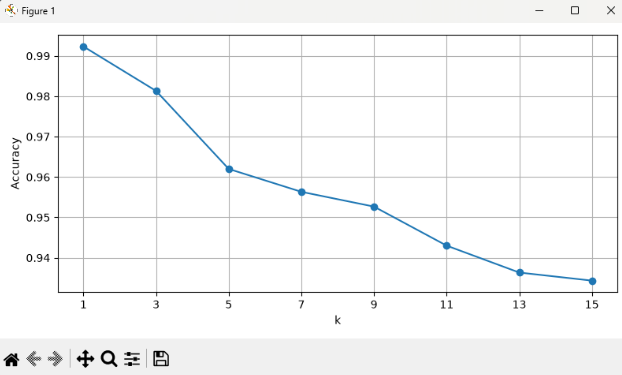

In [6]:
classifier = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
classifier.fit(X_train, y_train)

predicted = classifier.predict(X_test)
print('Accuracy, test:', accuracy_score(y_test, predicted))
print(classification_report(y_test, predicted, zero_division=0))

Accuracy, test: 0.9948807480617862
              precision    recall  f1-score   support

           (       0.99      0.99      0.99      4288
           )       1.00      1.00      1.00      4307
           +       1.00      1.00      1.00      7534
           ,       0.94      0.87      0.90       572
           -       1.00      1.00      1.00     10199
           0       1.00      1.00      1.00      2074
           1       0.98      1.00      0.99      7956
           2       1.00      1.00      1.00      7842
           3       1.00      1.00      1.00      3273
           4       1.00      0.99      1.00      2219
           5       1.00      1.00      1.00      1064
           6       1.00      0.99      1.00       936
           7       1.00      1.00      1.00       873
           8       1.00      0.99      1.00       920
           9       0.96      0.82      0.89       188
           X       1.00      1.00      1.00      7978
           h       0.99      0.99      0.99   

In [7]:
def generate_sequence(max_symbols=10, space_probability=0.25):
    images, gaps, text = [], [], []

    for i in range(random.randint(1, max_symbols)):
        label = random.choice(sorted(test_files))
        path = random.choice(test_files[label])

        image = cv2.imdecode(
            np.fromfile(path, np.uint8), cv2.IMREAD_GRAYSCALE
        )
        if image is None:
            raise ValueError(f'Не удалось прочитать {path}')

        images.append(image)

        if i:
            is_space = random.random() < space_probability
            gaps.append(45 if is_space else 10)
            if is_space:
                text.append(' ')

        text.append(SYMBOL_NAMES.get(label, label))

    height = max(img.shape[0] for img in images)
    width = 24 + sum(img.shape[1] for img in images) + sum(gaps)
    canvas = np.full((height + 24, width), 255, np.uint8)

    x = 12
    for i, image in enumerate(images):
        if i:
            x += gaps[i - 1]

        h, w = image.shape
        y = 12 + (height - h) // 2
        canvas[y:y+h, x:x+w] = image
        x += w

    return canvas, ''.join(text)

In [8]:
def recognize_sequence(image):
    gray = cv2.erode(image, np.ones((3, 3), np.uint8))
    _, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)

    contours, _ = cv2.findContours(
        binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    boxes = sorted(
        (cv2.boundingRect(c) for c in contours),
        key=lambda box: box[0]
    )
    boxes = [(x, y, w, h) for x, y, w, h in boxes if w * h > 50]

    marked = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
    if not boxes:
        return '', marked

    vectors = [
        prepare_symbol(image[y:y+h+3, x:x+w+5])
        for x, y, w, h in boxes
    ]
    predicted = classifier.predict(vectors)

    result = ''
    previous_end = None

    for (x, y, w, h), label in zip(boxes, predicted):
        if previous_end is not None and x - previous_end > 40:
            result += ' '

        result += SYMBOL_NAMES.get(label, label)
        previous_end = x + w

        cv2.rectangle(marked, (x, y), (x+w, y+h), (255, 0, 0), 1)

    return result, marked


Строка 1
Исходная:   70 9hh
Распознано: 70 yhh
Совпадение: False


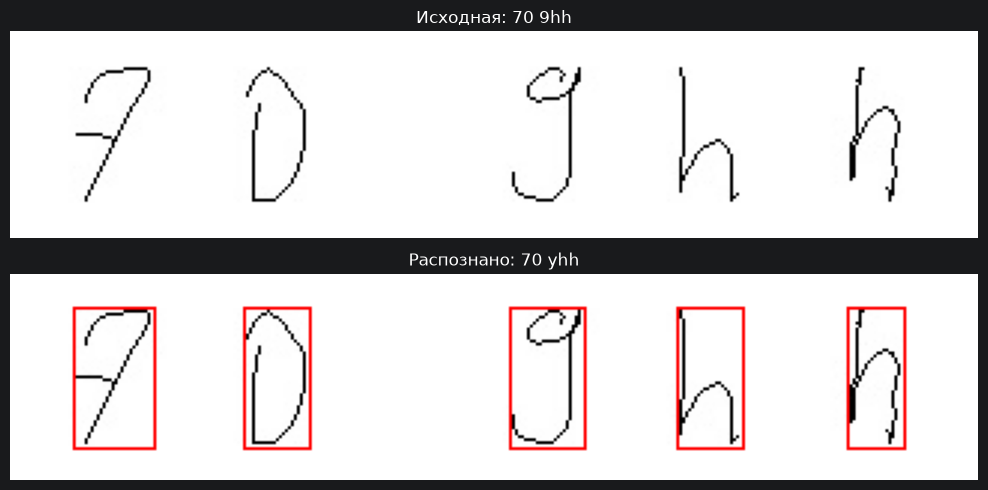


Строка 2
Исходная:   y
Распознано: y
Совпадение: True


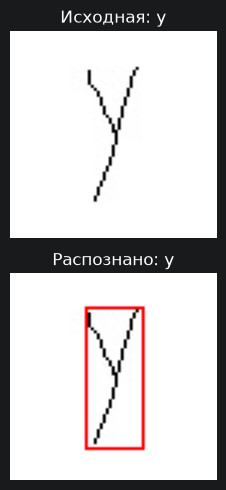


Строка 3
Исходная:   t+ 32× h 8
Распознано: t+ 32× h 8
Совпадение: True


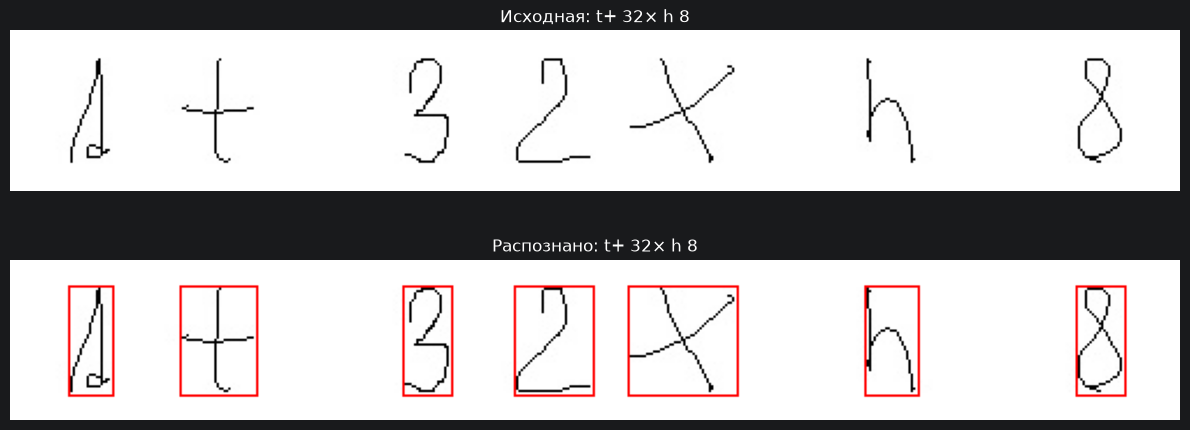


Строка 4
Исходная:   1 ,8 03+8h
Распознано: 1 ,8 03+8h
Совпадение: True


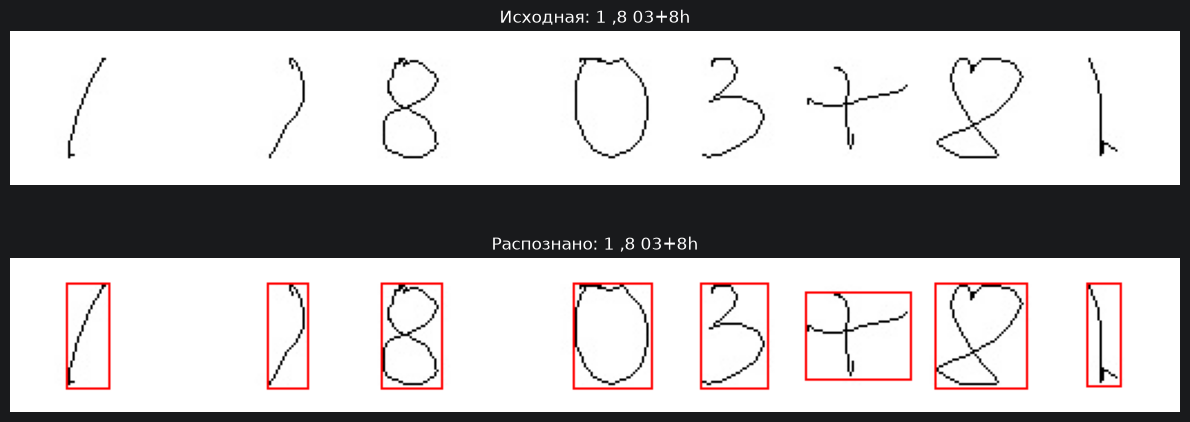


Строка 5
Исходная:   ×
Распознано: ×
Совпадение: True


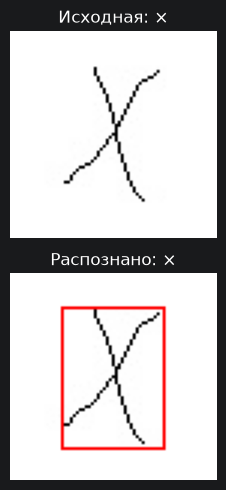


Полных совпадений: 4/5


In [9]:
matches = 0

for i in range(NUM_TESTS):
    image, expected = generate_sequence()
    recognized, marked = recognize_sequence(image)

    is_match = expected == recognized
    matches += int(is_match)

    print(f'\nСтрока {i + 1}')
    print('Исходная:  ', expected)
    print('Распознано:', recognized)
    print('Совпадение:', is_match)

    plt.figure(figsize=(12, 5))

    plt.subplot(2, 1, 1)
    plt.imshow(image, cmap='gray', vmin=0, vmax=255)
    plt.title('Исходная: ' + expected)
    plt.axis('off')

    plt.subplot(2, 1, 2)
    plt.imshow(marked)
    plt.title('Распознано: ' + recognized)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

print(f'\nПолных совпадений: {matches}/{NUM_TESTS}')